# Лабораторна № 2
**Мета:** засвоїти основні відомості про роботу з алгоритмом метод головних компонент (PCA) та дерева рішень для класифікаційних завдань.


## Завдання 1. Підготовка даних


**Імпорти та завантаження.** 

pd.read_csv читає файл у таблицю (DataFrame). df.head() показує перші 5 рядків.

(569 пацієнтів і 33 колонки)

In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

df = pd.read_csv('data.csv')
print(df.shape)
df.head()

(569, 33)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


**Перевірка NaN і очищення**

Пропущені значення (NaN) містяться лише в колонці Unnamed: 32, яка є повністю порожньою (569 з 569 значень). Це технічний артефакт CSV-файлу (кома в кінці рядка заголовка). Тому замість заповнення середнім чи видалення рядків доцільно видалити саму колонку. Так ми не втрачаємо жодного запису. Колонку id також видалено, бо вона не несе інформації для класифікації.

Класи незбалансовані. Злоякісних 212 / 569 ≈ 37%, доброякісних ≈ 63%. Тому ми використаємо stratify=y, щоб пропорція збереглась у train, val і test.

In [32]:
# Скільки NaN у кожній колонці
na = df.isna().sum()
print(na[na > 0])

# Видаляємо службові колонки
df = df.drop(columns=['id', 'Unnamed: 32'])

# Діагноз до числа
df['diagnosis'] = df['diagnosis'].map({'M': 1, 'B': 0})

print(df.shape)
print(df['diagnosis'].value_counts())

# M (злоякісна), B (доброякісна)

Unnamed: 32    569
dtype: int64
(569, 31)
diagnosis
0    357
1    212
Name: count, dtype: int64


**Розділення X / y та 70/15/15**

тренувальна, валідаційна та тестова вибірки

train_test_split вміє ділити тільки на дві частини. Тому ділимо двічі: спочатку 70/30, потім 30 навпіл. random_state=42 фіксує випадковість. Кожного разу розбиття буде однакове, і результати не «стрибатимуть». stratify=y означає, що в кожній вибірці буде однакова частка M і B (~37% злоякісних). Без цього могло б статись, що у val майже немає M.

In [33]:
X = df.drop(columns=['diagnosis'])
y = df['diagnosis']

# 70, 30
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y)

# 15, 15
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp)

print('Train:', X_train.shape)
print('Val:  ', X_val.shape)
print('Test: ', X_test.shape)

Train: (398, 30)
Val:   (85, 30)
Test:  (86, 30)


**Нормалізація**

Для кожної ознаки на **тренувальній** вибірці обраховуємо середнє (mean) та стандартне відхилення (std) і перетворюємо дані: `(x − mean) / std`. Після цього кожна ознака має середнє 0 і std 1, тобто всі ознаки в однаковому масштабі.

Валідаційну й тестову вибірки нормалізуємо **тими самими** mean і std, що й train. Якщо рахувати статистики разом з ними, модель «підгляне» в дані, які мають бути для неї новими (data leakage).

In [34]:
# mean і std рахуємо на train
train_mean = X_train.mean()
train_std  = X_train.std()

# Застосовуємо ці самі значення до всіх трьох вибірок
X_train_norm = (X_train - train_mean) / train_std
X_val_norm   = (X_val   - train_mean) / train_std
X_test_norm  = (X_test  - train_mean) / train_std

print('Середнє train після нормалізації (має бути ~0):')
print(X_train_norm.mean().round(3).head())
print('\nStd train після нормалізації (має бути 1):')
print(X_train_norm.std().round(3).head())

Середнє train після нормалізації (має бути ~0):
radius_mean        0.0
texture_mean      -0.0
perimeter_mean     0.0
area_mean          0.0
smoothness_mean   -0.0
dtype: float64

Std train після нормалізації (має бути 1):
radius_mean        1.0
texture_mean       1.0
perimeter_mean     1.0
area_mean          1.0
smoothness_mean    1.0
dtype: float64


**Візуальна перевірка**

На графіку видно, що зліва area в сотні разів більша за інші ознаки, а справа всі три в одному масштабі навколо 0

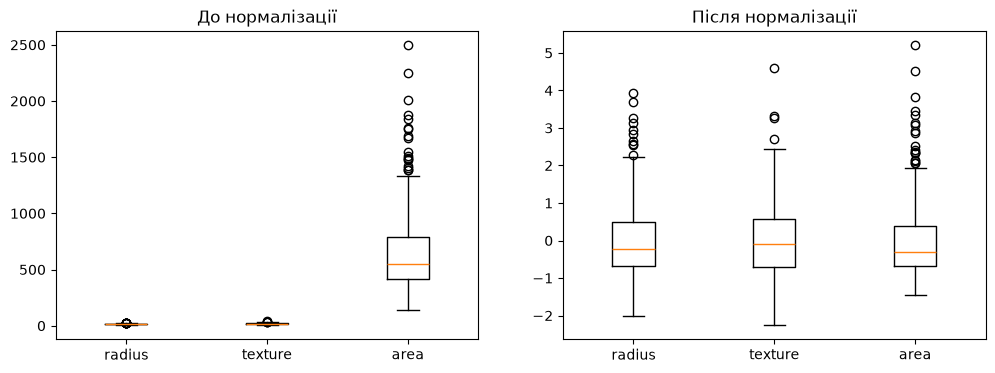

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].boxplot(X_train[['radius_mean', 'texture_mean', 'area_mean']])
axes[0].set_xticklabels(['radius', 'texture', 'area'])
axes[0].set_title('До нормалізації')

axes[1].boxplot(X_train_norm[['radius_mean', 'texture_mean', 'area_mean']])
axes[1].set_xticklabels(['radius', 'texture', 'area'])
axes[1].set_title('Після нормалізації')
plt.show()

## Завдання 2. Побудова дерева рішень

**Глибина дерева (max_depth**) — це скільки запитань поспіль дерево може поставити, поки не дасть відповідь.


**Імпорти**

DecisionTreeClassifier — сама модель дерева.  
plot_tree — малює дерево.  
accuracy_score — рахує точність: частку правильних відповідей.  

In [36]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score

**Функція «навчи і оціни»**

DecisionTreeClassifier(max_depth=d, criterion='gini', ...) створює дерево  
criterion='gini' означає, що найкраще запитання дерево вибирає за індексом Gini  

In [37]:
def train_and_evaluate(X_tr, y_tr, X_v, y_v, depths, title=''):
    """Навчає дерева з різною глибиною і повертає їх разом з точностями."""
    trees = {}
    results = []
    for d in depths:
        tree = DecisionTreeClassifier(max_depth=d, criterion='gini', random_state=42)
        tree.fit(X_tr, y_tr) # навчання

        train_acc = accuracy_score(y_tr, tree.predict(X_tr)) # точність на train
        val_acc = accuracy_score(y_v,  tree.predict(X_v)) # точність на val

        trees[d] = tree
        results.append({'max_depth': d,
                        'leaves': tree.get_n_leaves(),
                        'train_acc': round(train_acc, 3),
                        'val_acc': round(val_acc, 3)})
    df_res = pd.DataFrame(results)
    print(title)
    display(df_res)
    return trees, df_res

**Навчаємо три дерева**

In [38]:
depths = [2, 4, 8]
trees_clean, res_clean = train_and_evaluate(
    X_train_norm, y_train, X_val_norm, y_val, depths,
    title='Дерева на чистих даних')

Дерева на чистих даних


,max_depth,leaves,train_acc,val_acc
0,2,4,0.950,0.882
1,4,9,0.977,0.894
2,8,19,1.000,0.894


**Візуалізація дерев**

Оанжеві - переважно B, сині - переважно M.   
Чим насиченіший колір, тим «чистіший» вузол.


Як читати вузол дерева на картинці:
| Рядок | Значення |
| :--- | :--- |
| `perimeter_worst <= 0.16` | **Запитання.** Якщо так, ідемо **ліворуч**, якщо ні - **праворуч**. 0.16 - це нормалізоване значення, тобто трохи більше за середнє. |
| `gini = 0.468` | Наскільки «змішані» класи у вузлі. 0 означає, що тут лише один клас; 0.5 - максимальна мішанина (для двох класів). |
| `samples = 398` | Скільки пацієнтів дійшло до цього вузла. У корені це весь train. |
| `value = [250, 148]` | Скільки з них B і скільки M. |
| `class = B (0)` | Що дерево відповість, якщо зупиниться тут, тобто клас більшості. |

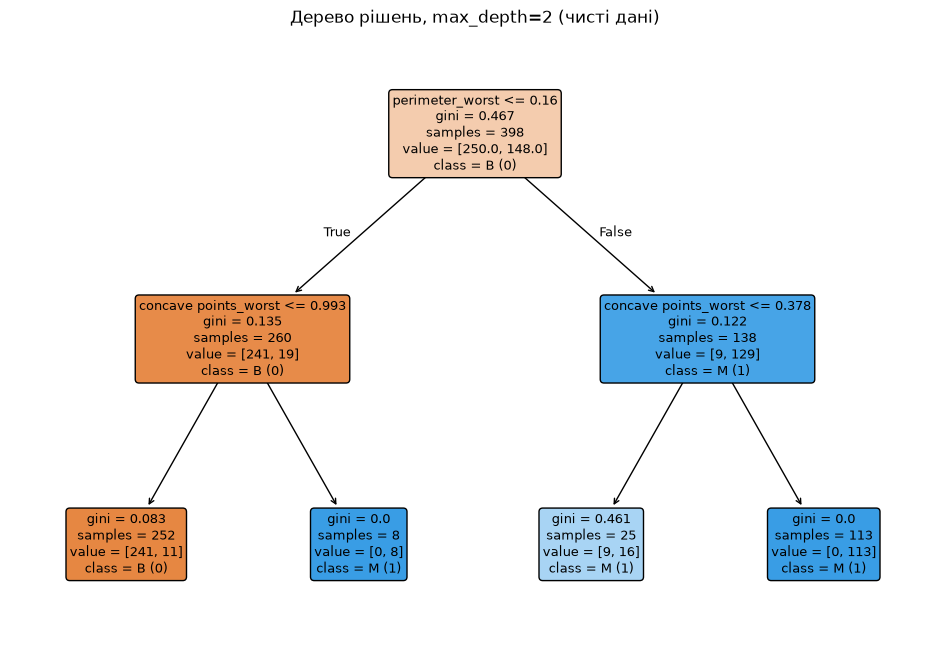

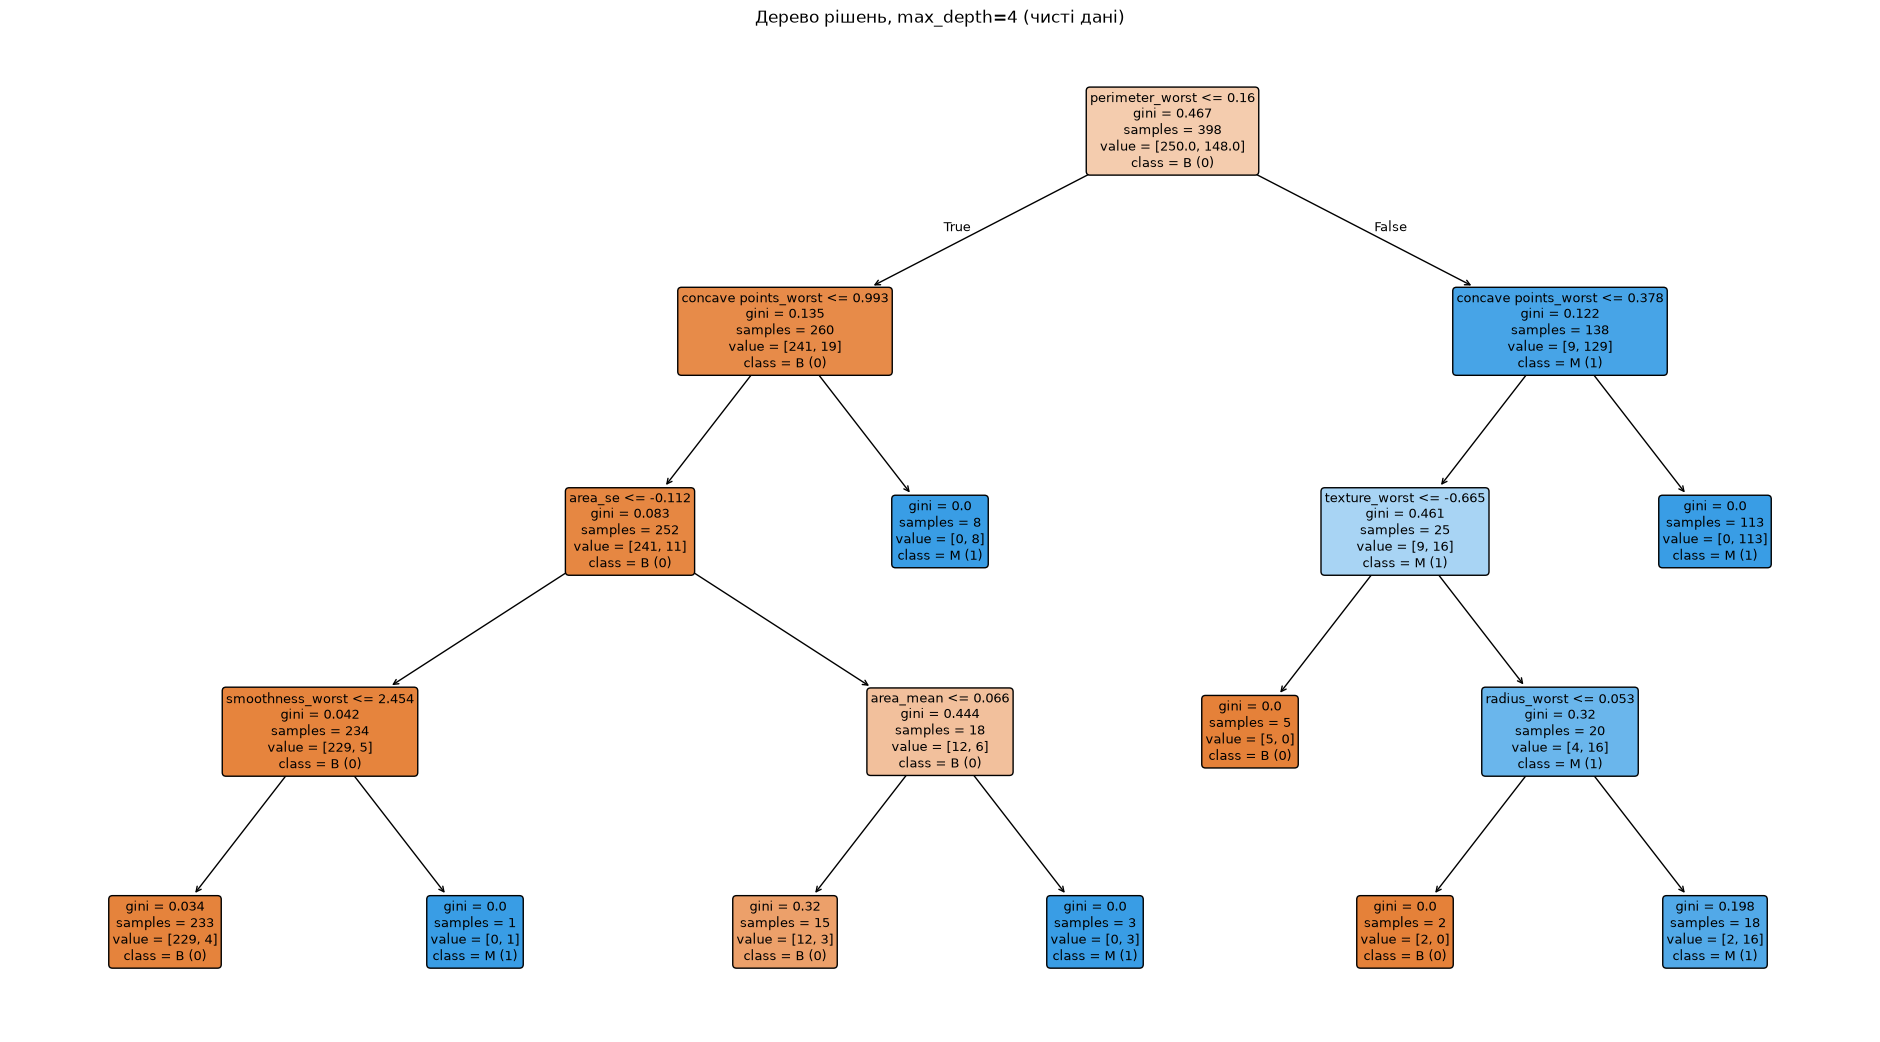

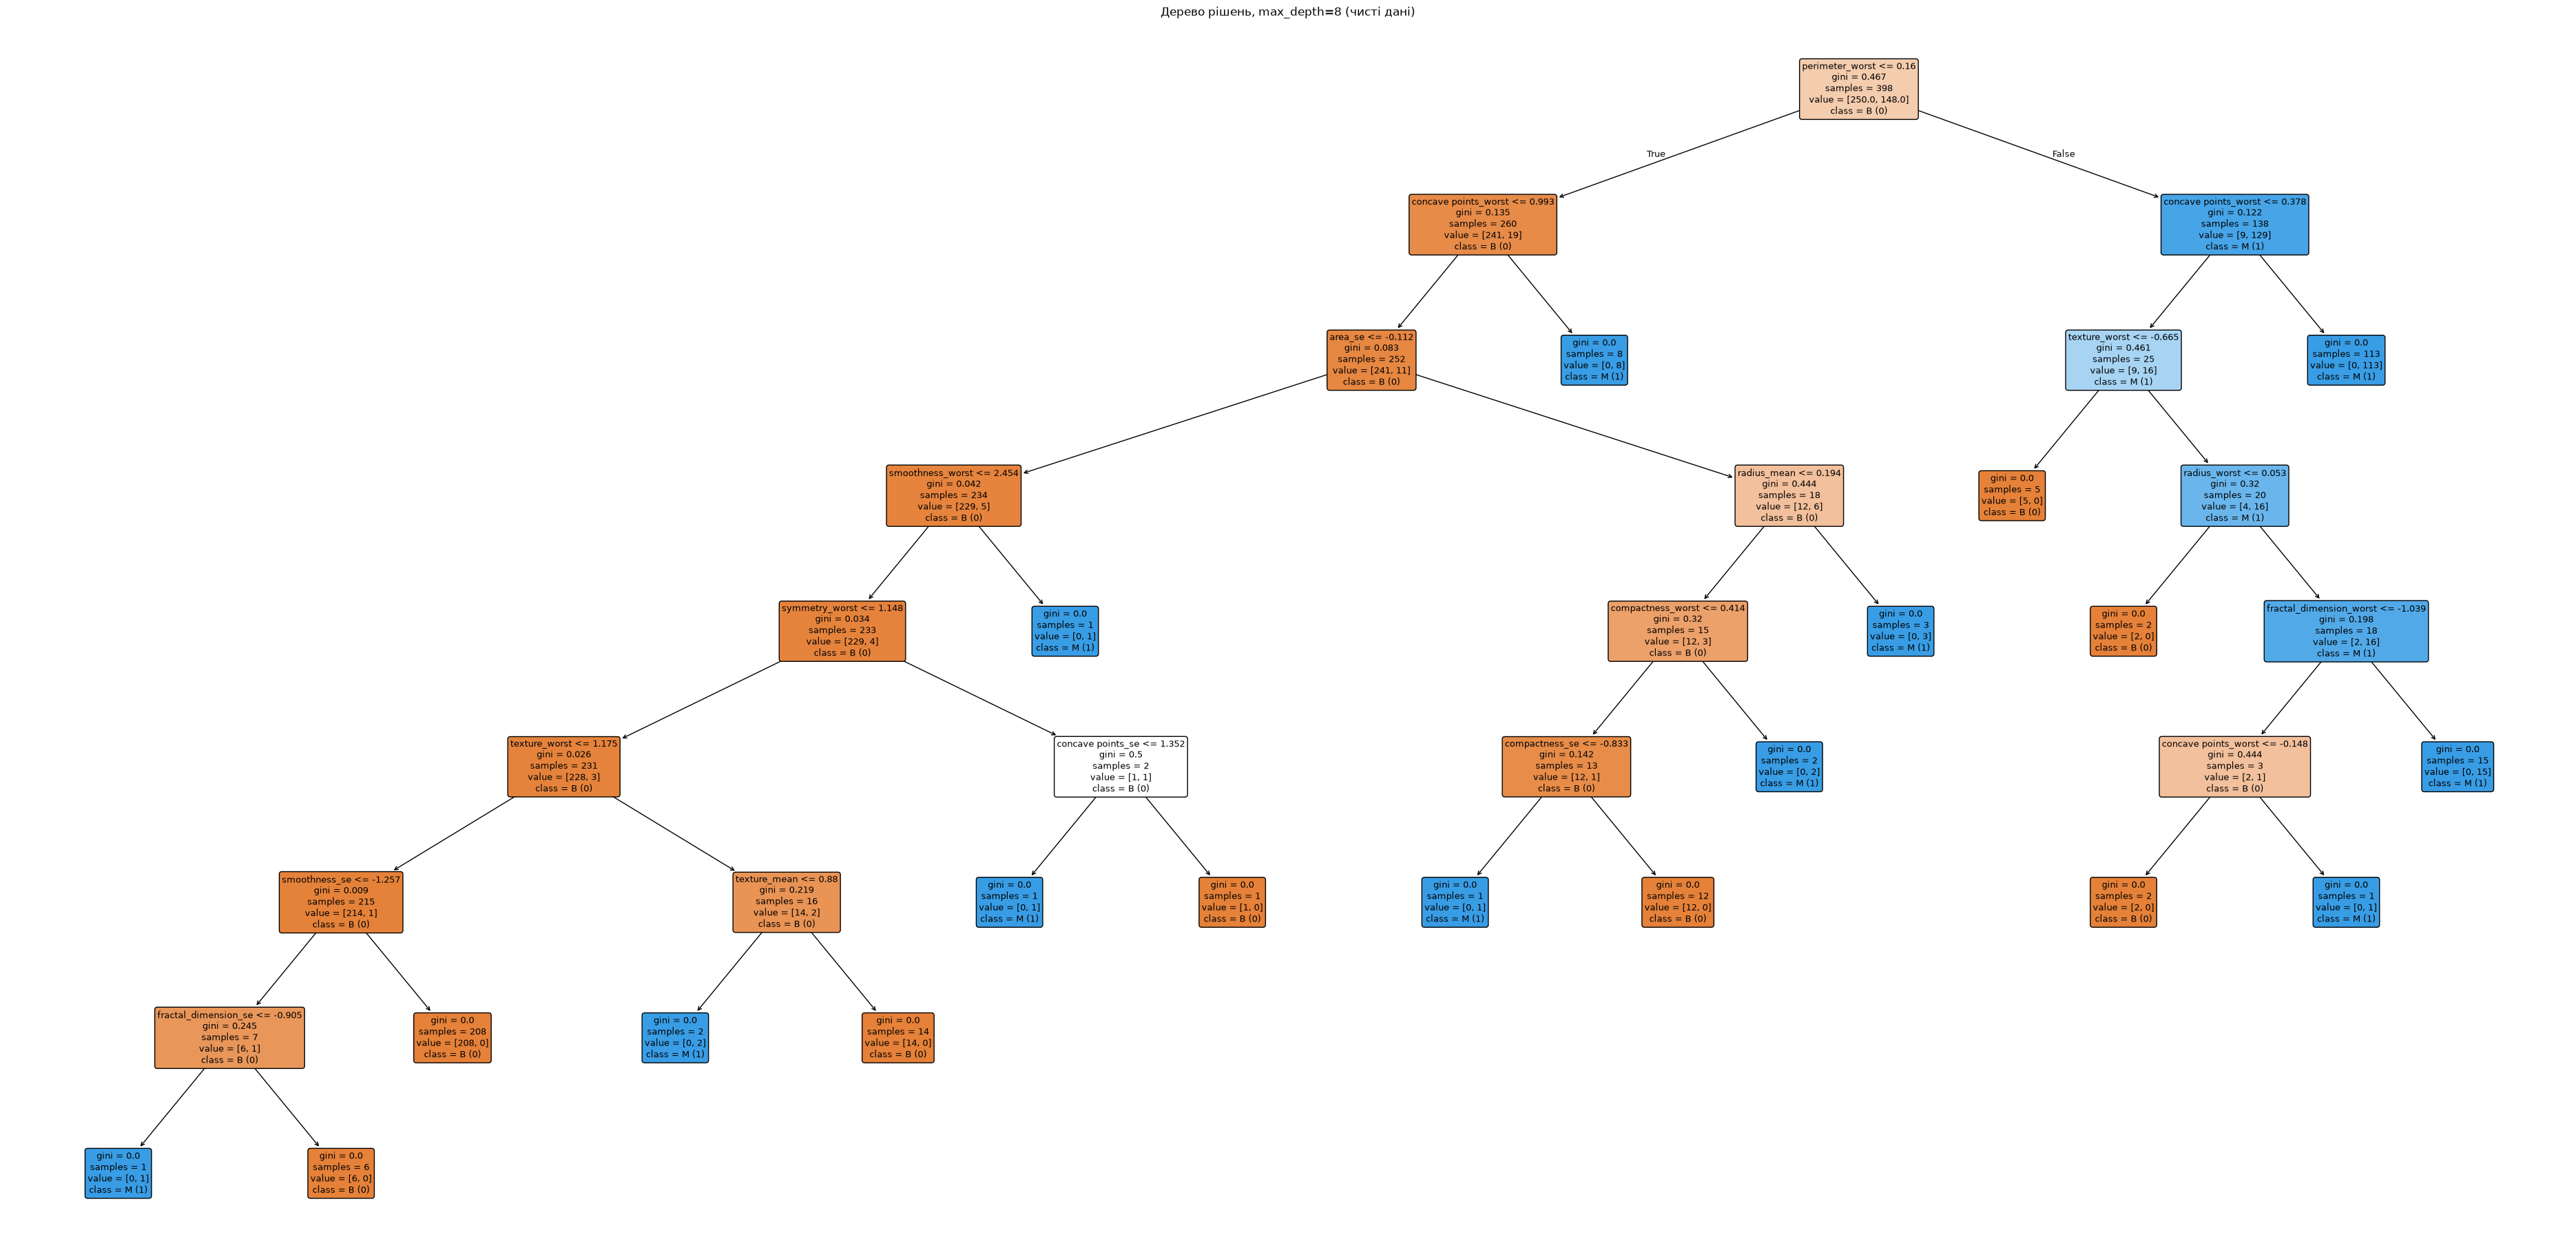

In [39]:
for d, tree in trees_clean.items():
    plt.figure(figsize=(6 * d, 2.5 * d + 3))
    plot_tree(tree,
              feature_names=X_train_norm.columns,
              class_names=['B (0)', 'M (1)'],
              filled=True, rounded=True, fontsize=9)
    plt.title(f'Дерево рішень, max_depth={d} (чисті дані)')
    plt.show()

**Глибина 2.** Дерево дуже просте (4 листки), але вже має 95% на train і 88% на val. Двох запитань майже достатньо, щоб відрізнити злоякісну пухлину.  
**Глибина 4.** Train 97.7%, val 89.4%. Це найкращий баланс: дерево ще не надто складне, а точність на валідації найвища.  
**Глибина 8.** Train 100%, тобто дерево безпомилково «запам'ятало» кожного пацієнта з train. Але на val ті самі 89.4%, кращого результату немає. Це перенавчання (overfitting): дерево вивчило не загальні закономірності, а дрібні особливості конкретних 398 пацієнтів. 19 листків замість 9 не дали жодного виграшу на нових даних.  

**Графік порівняння точності**

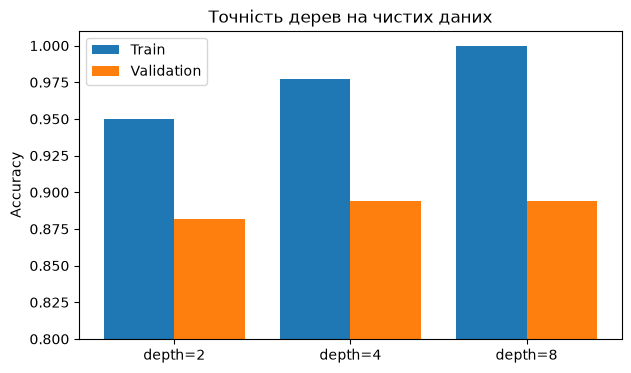

In [40]:
x = np.arange(len(depths))
plt.figure(figsize=(7, 4))
plt.bar(x - 0.2, res_clean['train_acc'], width=0.4, label='Train')
plt.bar(x + 0.2, res_clean['val_acc'],   width=0.4, label='Validation')
plt.xticks(x, [f'depth={d}' for d in depths])
plt.ylim(0.8, 1.01)
plt.ylabel('Accuracy')
plt.title('Точність дерев на чистих даних')
plt.legend()
plt.show()

## Завдання 3. Зашумлення

**Шум** - це маленькі випадкові похибки в даних. У реальному житті вони бувають завжди: прилад трохи неточно виміряв, лікар округлив, сканер дав похибку.  
До кожного елемента масиву `X_train_norm` додається випадкове значення від -0.1 до 0.1 із рівномірною ймовірністю.  
Шум додаємо тільки до train. Validation і test не чіпаємо, бо вони імітують справжні нові дані, на яких ми перевіряємо модель.


**Створення шуму**

In [41]:
np.random.seed(42)   # фіксуємо випадковість, щоб шум щоразу був однаковий

noise = np.random.uniform(low=-0.1, high=0.1, size=X_train_norm.shape)
X_train_noisy = X_train_norm + noise

print('Розмір шуму:', noise.shape)
print('Мінімум шуму:', noise.min().round(4))
print('Максимум шуму:', noise.max().round(4))
print('Середнє шуму:', noise.mean().round(4))

Розмір шуму: (398, 30)
Мінімум шуму: -0.1
Максимум шуму: 0.0999
Середнє шуму: -0.0008


**Порівняння «до» і «після» на одному пацієнті**



In [42]:
compare = pd.DataFrame({
    'Чисті':      X_train_norm.iloc[0, :5],
    'Шум':        noise[0, :5],
    'Зашумлені':  X_train_noisy.iloc[0, :5]
}).round(3)
compare



,Чисті,Шум,Зашумлені
radius_mean,1.704,-0.025,1.679
texture_mean,1.048,0.090,1.139
perimeter_mean,2.119,0.046,2.165
area_mean,1.667,0.020,1.687
smoothness_mean,2.274,-0.069,2.205


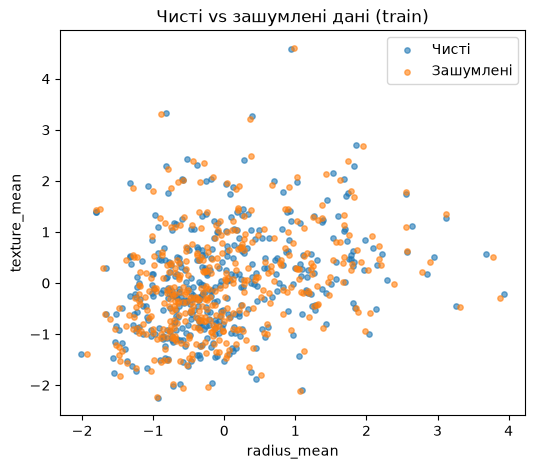

In [43]:
plt.figure(figsize=(6, 5))
plt.scatter(X_train_norm['radius_mean'], X_train_norm['texture_mean'],
            s=15, alpha=0.6, label='Чисті')
plt.scatter(X_train_noisy['radius_mean'], X_train_noisy['texture_mean'],
            s=15, alpha=0.6, label='Зашумлені')
plt.xlabel('radius_mean'); plt.ylabel('texture_mean')
plt.title('Чисті vs зашумлені дані (train)')
plt.legend()
plt.show()

**Три дерева на зашумлених даних**  
Навчаємо на X_train_noisy

In [44]:
trees_noisy, res_noisy = train_and_evaluate(
    X_train_noisy, y_train, X_val_norm, y_val, depths,
    title='Дерева на зашумлених даних')

Дерева на зашумлених даних


,max_depth,leaves,train_acc,val_acc
0,2,4,0.952,0.894
1,4,9,0.975,0.882
2,8,18,0.997,0.906


**Візуалізація дерев**

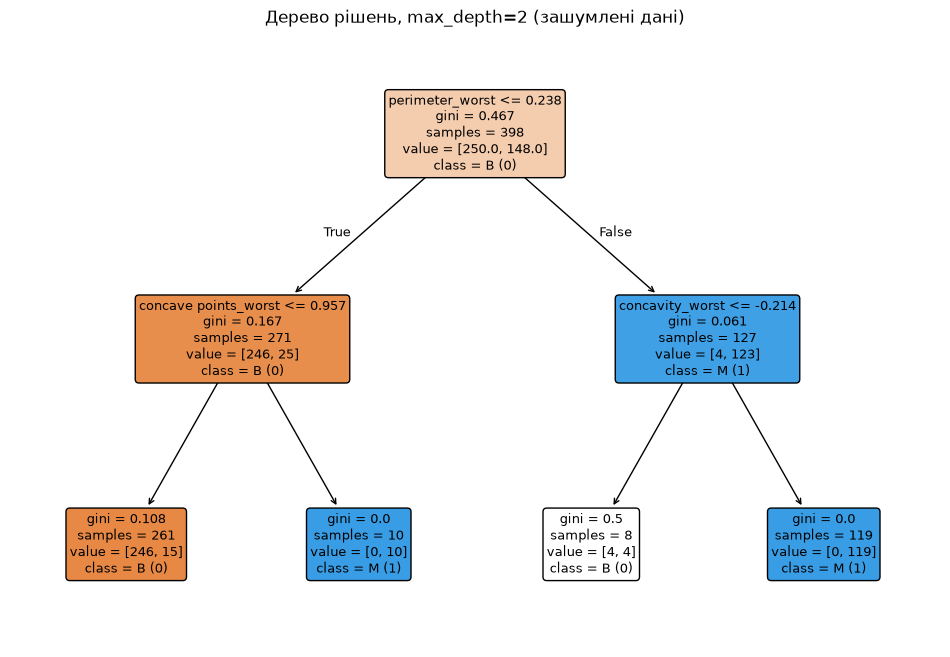

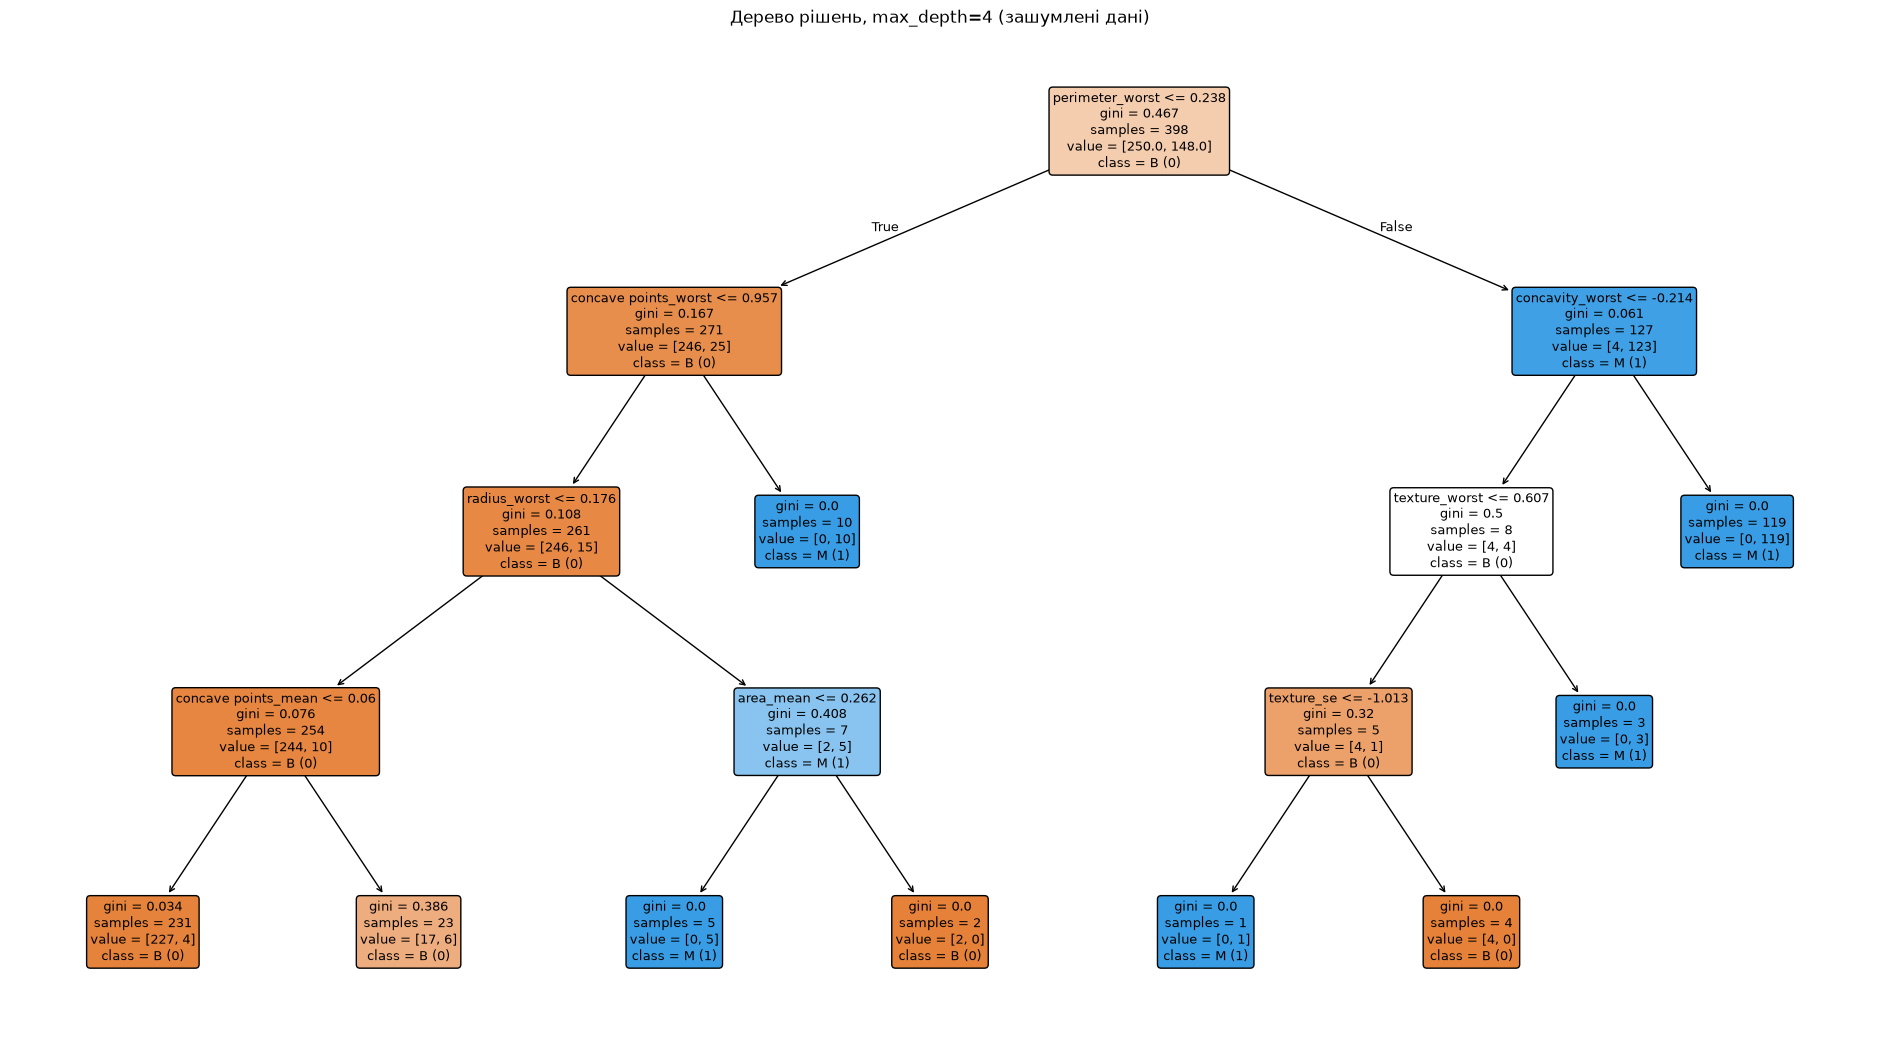

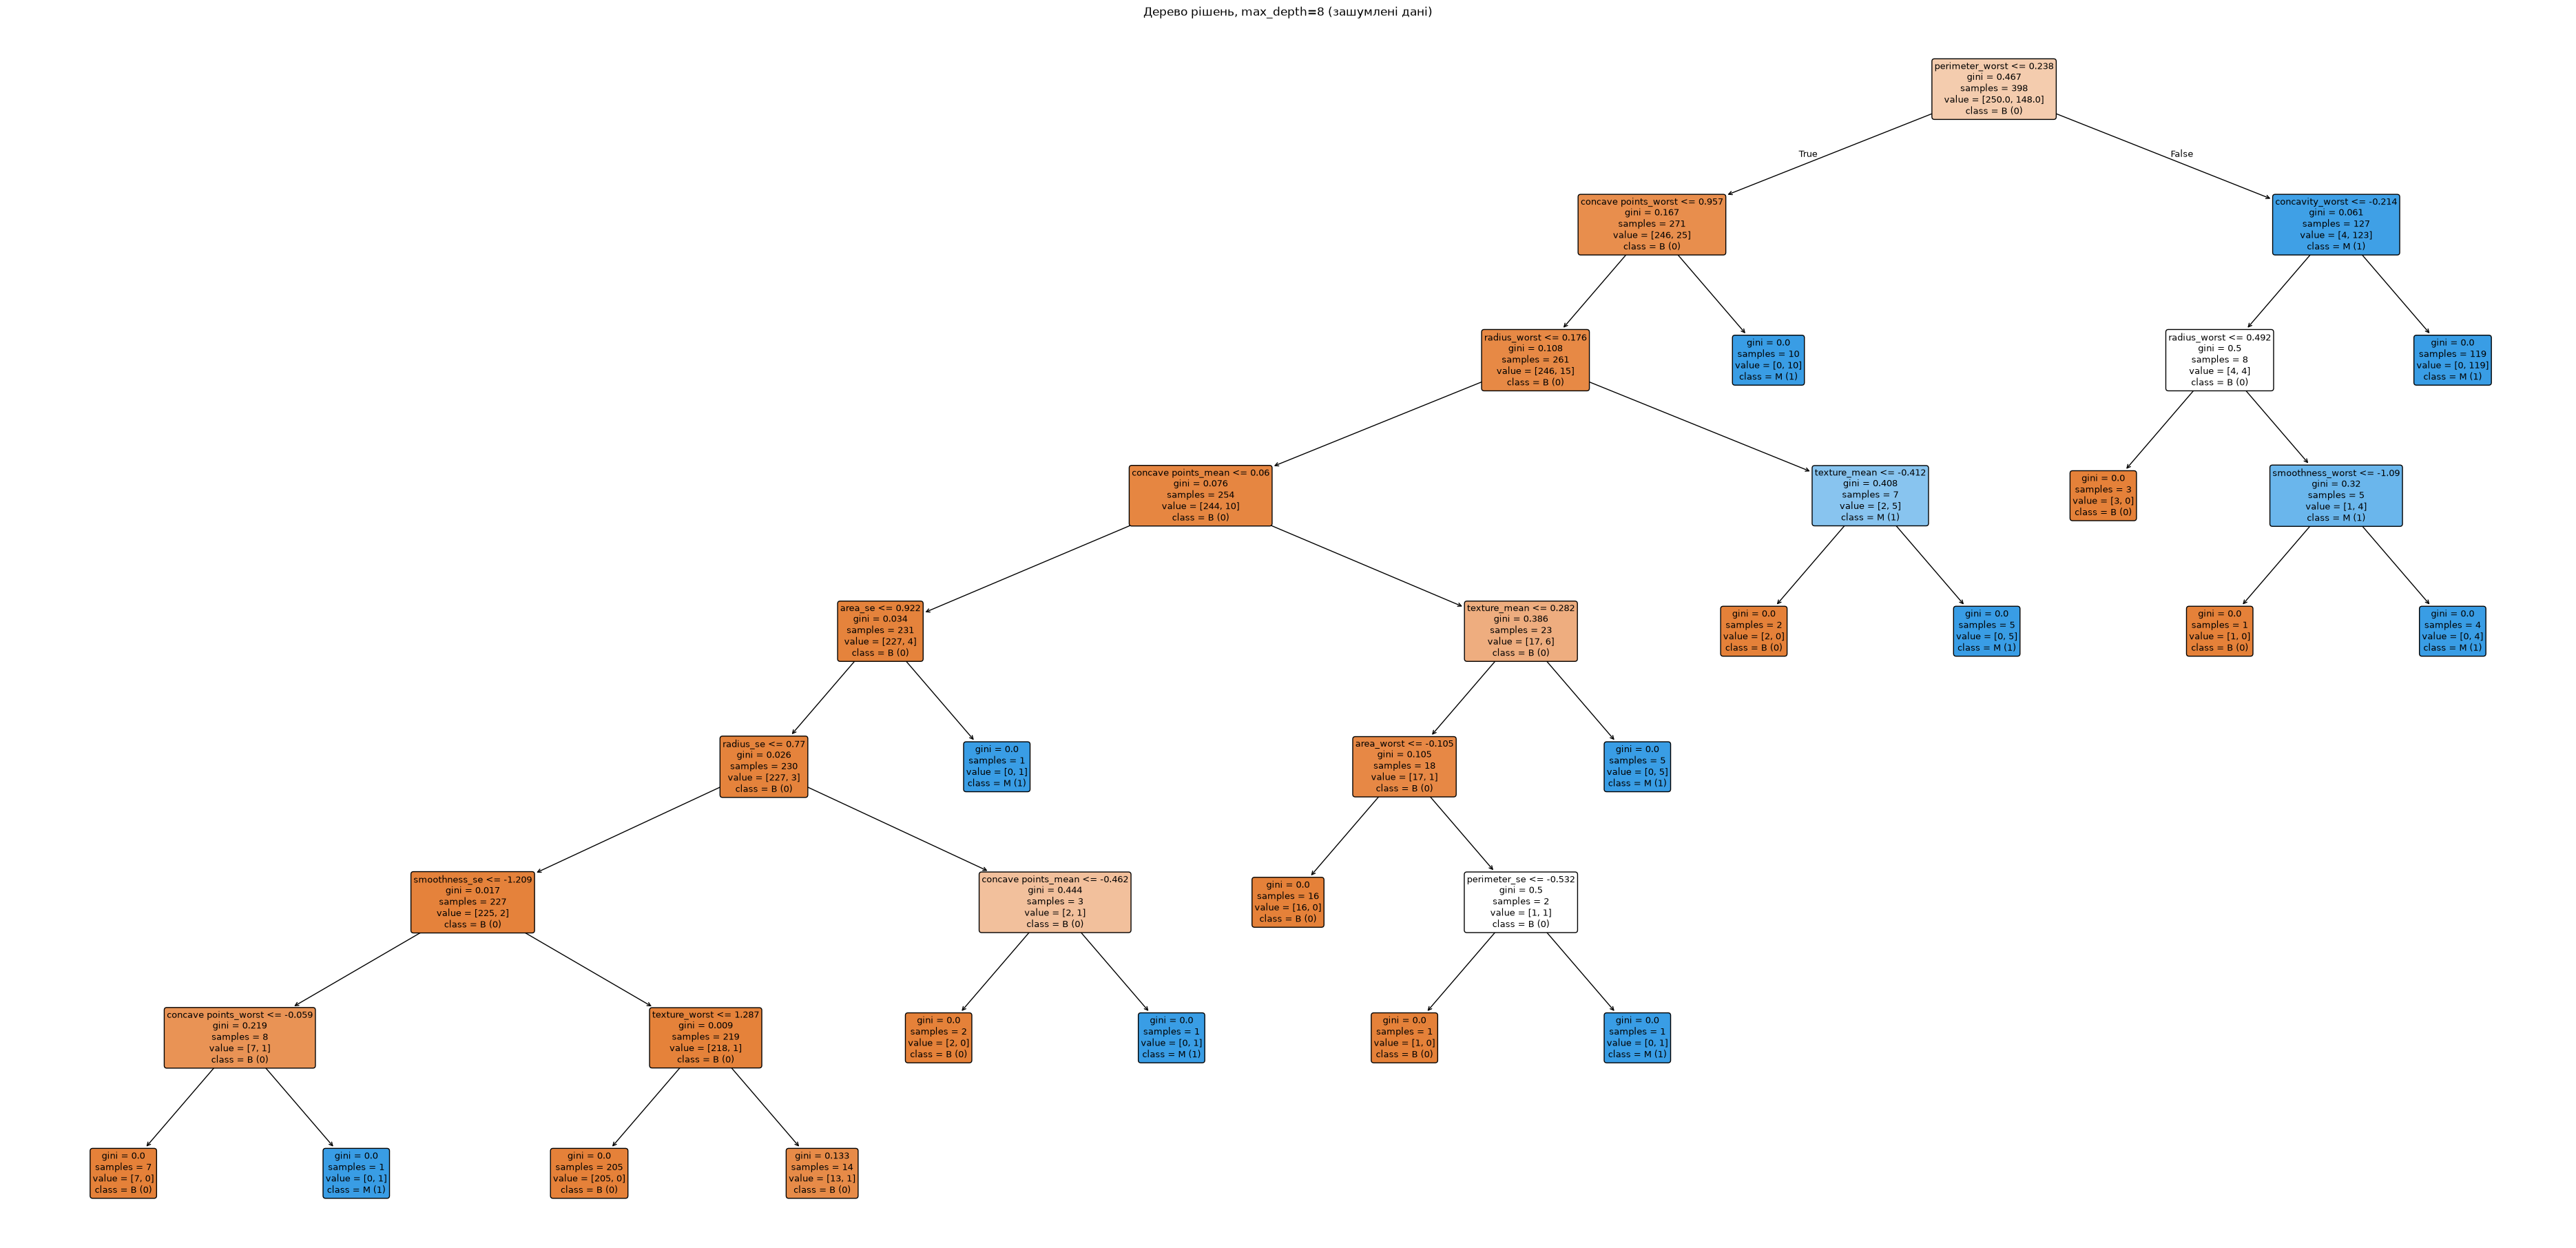

In [45]:
for d, tree in trees_noisy.items():
    plt.figure(figsize=(6 * d, 2.5 * d + 3))
    plot_tree(tree,
              feature_names=X_train_noisy.columns,
              class_names=['B (0)', 'M (1)'],
              filled=True, rounded=True, fontsize=9)
    plt.title(f'Дерево рішень, max_depth={d} (зашумлені дані)')
    plt.show()

**Порівняльний графік «чисті vs зашумлені»**

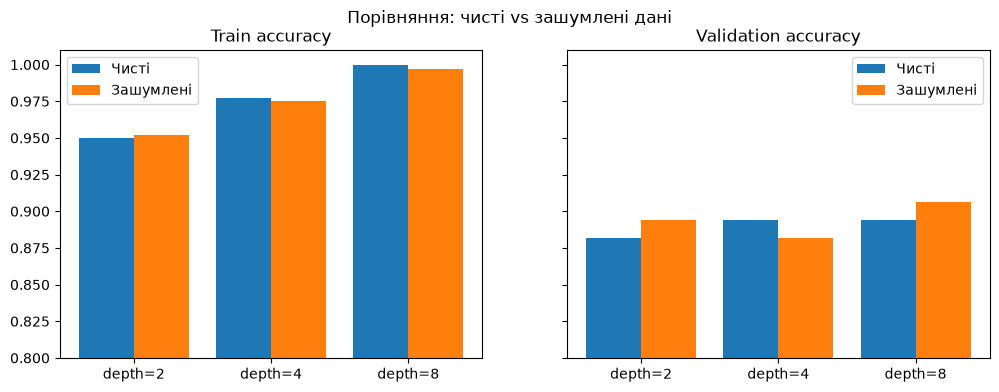

In [46]:
x = np.arange(len(depths))
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for ax, col, name in zip(axes, ['train_acc', 'val_acc'], ['Train', 'Validation']):
    ax.bar(x - 0.2, res_clean[col], width=0.4, label='Чисті')
    ax.bar(x + 0.2, res_noisy[col], width=0.4, label='Зашумлені')
    ax.set_xticks(x)
    ax.set_xticklabels([f'depth={d}' for d in depths])
    ax.set_title(f'{name} accuracy')
    ax.set_ylim(0.8, 1.01)
    ax.legend()

plt.suptitle('Порівняння: чисті vs зашумлені дані')
plt.show()

**Висновки:** Додавання шуму [−0.1, 0.1] майже не вплинуло на точність моделей (коливання в межах 1.2%), оскільки для нормалізованих даних він є надто дрібним і губиться на їхньому тлі. Структура дерев також здебільшого збереглася: у корені залишилася та сама ознака (`perimeter_worst`), а оновилися лише пороги розбиття та гілки на нижніх рівнях. Єдиний суттєвий наслідок - дерево з глибиною 8 більше не видає 100% точності на тренувальних даних, адже через шум моделі стало складніше їх ідеально завчити.

## Завдання 4. Знешумлення

**Метод головних компонент (PCA)** - це статистичний алгоритм, який перетворює набір залежних між собою ознак на нові, абсолютно незалежні одна від одної змінні (головні компоненти).  
**«explained variance» (пояснена дисперсія)** - Це яка частка всієї інформації (розкиду) в даних припадає на кожну компоненту.

#### Як PCA прибирає шум (ідея знешумлення)

1. Справжня інформація зосереджена в **перших компонентах**, оскільки там найбільший розкид даних.
2. Шум є випадковим, тому він «розмазується» рівномірно по всіх 30 напрямках.
3. В **останніх компонентах** (PC11–PC30) корисної інформації майже немає, отже там міститься переважно шум.
4. Відкидаємо ці компоненти та реконструюємо початкові 30 ознак (за допомогою `inverse_transform`). Разом із компонентами відкидається й частина шуму.


**Імпорт і PCA на чистих та зашумлених даних**

In [47]:
from sklearn.decomposition import PCA

pca_clean = PCA()
pca_clean.fit(X_train_norm)

pca_noisy = PCA()
pca_noisy.fit(X_train_noisy)

print('Explained variance ratio (перші 10), чисті:')
print(pca_clean.explained_variance_ratio_[:10].round(3))
print('Explained variance ratio (перші 10), зашумлені:')
print(pca_noisy.explained_variance_ratio_[:10].round(3))

Explained variance ratio (перші 10), чисті:
[0.437 0.192 0.097 0.067 0.056 0.041 0.022 0.016 0.013 0.012]
Explained variance ratio (перші 10), зашумлені:
[0.435 0.192 0.097 0.067 0.056 0.041 0.022 0.016 0.013 0.012]


**Графік поясненої дисперсії**

Стовпчики - внесок кожної компоненти. Перший високий, далі вони швидко спадають  
Червона лінія - накопичена сума: PC1, потім PC1+PC2, потім PC1+PC2+PC3…  
Сіра пунктирна лінія на 95%. Червона лінія перетинає її на 10-й компоненті  

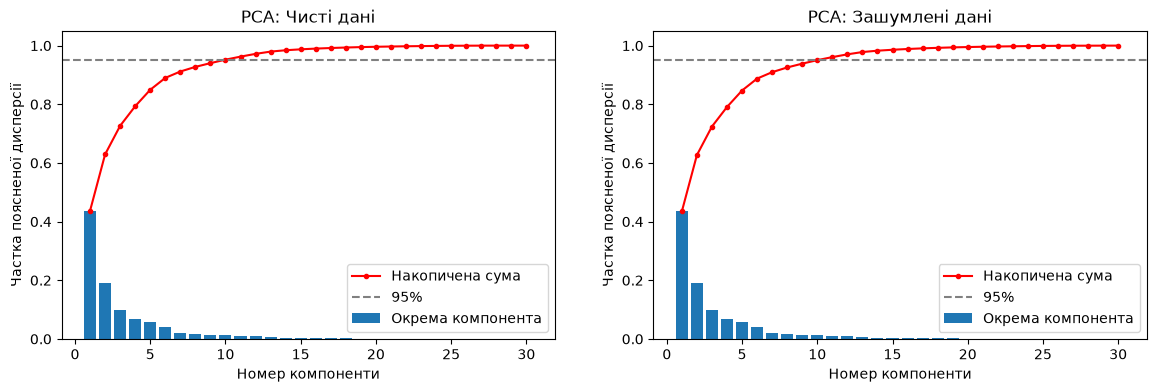

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for ax, pca, name in zip(axes, [pca_clean, pca_noisy], ['Чисті дані', 'Зашумлені дані']):
    n = len(pca.explained_variance_ratio_)
    ax.bar(range(1, n + 1), pca.explained_variance_ratio_, label='Окрема компонента')
    ax.plot(range(1, n + 1), np.cumsum(pca.explained_variance_ratio_),
            'ro-', markersize=3, label='Накопичена сума')
    ax.axhline(0.95, color='gray', linestyle='--', label='95%')
    ax.set_xlabel('Номер компоненти')
    ax.set_ylabel('Частка поясненої дисперсії')
    ax.set_title(f'PCA: {name}')
    ax.legend()

plt.show()

**Дані в просторі перших двох компонент**

сині точки (B) і червоні (M) майже чітко розділені вздовж PC1. Тобто одна компонента, «загальний розмір і нерівність пухлини», вже сама добре відрізняє злоякісну пухлину від доброякісної. Чисті й зашумлені дані виглядають майже однаково

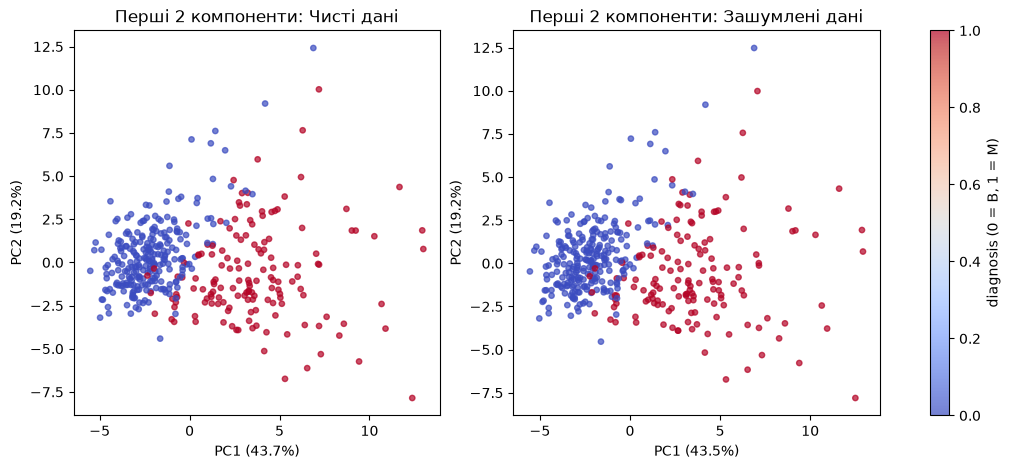

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, pca, data, name in zip(axes,
                               [pca_clean, pca_noisy],
                               [X_train_norm, X_train_noisy],
                               ['Чисті дані', 'Зашумлені дані']):
    Z = pca.transform(data)              # переводимо у простір компонент
    sc = ax.scatter(Z[:, 0], Z[:, 1], c=y_train, cmap='coolwarm', s=15, alpha=0.7)
    ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%})')
    ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%})')
    ax.set_title(f'Перші 2 компоненти: {name}')

plt.colorbar(sc, ax=axes, label='diagnosis (0 = B, 1 = M)')
plt.show()

**З чого складаються компоненти (heatmap)**

Кожне число показує, наскільки сильно ознака входить у компоненту. Червоне означає позитивний внесок, синє - негативний, близьке до 0 - ознака майже не впливає.

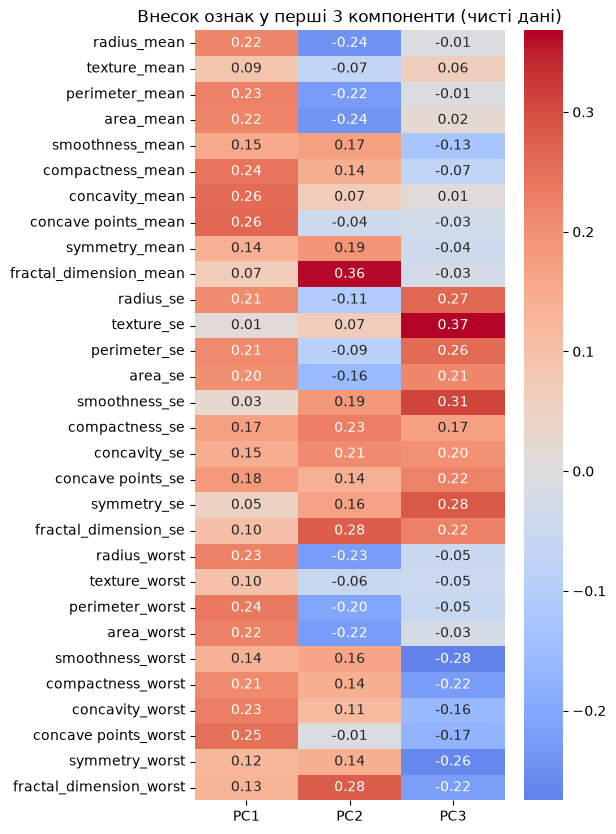

In [50]:
loadings = pd.DataFrame(pca_clean.components_[:3].T,
                        index=X_train_norm.columns,
                        columns=['PC1', 'PC2', 'PC3'])

plt.figure(figsize=(5, 10))
sns.heatmap(loadings, cmap='coolwarm', center=0, annot=True, fmt='.2f')
plt.title('Внесок ознак у перші 3 компоненти (чисті дані)')
plt.show()

**Знешумлення: PCA на 95%**

Ідея: стиснути дані до кількох головних компонент, а потім відновити їх назад. Під час стискання відкидаються найменш важливі компоненти, разом із якими зникає частина шуму.

1. `PCA(n_components=0.95).fit(X_train_noisy)` - PCA навчається на **зашумлених** даних (як у реальному житті, де чистих даних немає) і залишає мінімальну кількість компонент, що разом пояснюють ≥ 95% дисперсії. Для наших даних це **10 компонент** з 30 (95.04%); компоненти PC11–PC30 відкидаються.
2. `transform` - кожен пацієнт описується вже не 30 ознаками, а 10 значеннями головних компонент: форма `(398, 30) → (398, 10)`.
3. `inverse_transform` - відновлюємо 30 початкових ознак з 10 компонент: `(398, 10) → (398, 30)`. Оскільки інформація з відкинутих компонент втрачена, відновлені дані «згладжені»: загальна структура зберігається, а дрібні відхилення (зокрема шум) зникають.

In [51]:
pca_95 = PCA(n_components=0.95) # залишити стільки компонент, щоб пояснити 95%
pca_95.fit(X_train_noisy) # навчаємо на зашумлених

print('Кількість компонент для 95%:', pca_95.n_components_)
print('Сумарна пояснена дисперсія:', pca_95.explained_variance_ratio_.sum().round(4))

components = pca_95.transform(X_train_noisy) # 30 ознак -> 10 компонент
X_train_denoised = pca_95.inverse_transform(components) # 10 компонент -> 30 ознак

# Повертаємо назад в DataFrame
X_train_denoised = pd.DataFrame(X_train_denoised,
                                columns=X_train_norm.columns,
                                index=X_train_norm.index)
print('Форма:', components.shape, '->', X_train_denoised.shape)

Кількість компонент для 95%: 10
Сумарна пояснена дисперсія: 0.9504
Форма: (398, 10) -> (398, 30)


**Візуалізація: оригінальні, зашумлені, знешумлені**

Графік 1: scatter двох ознак


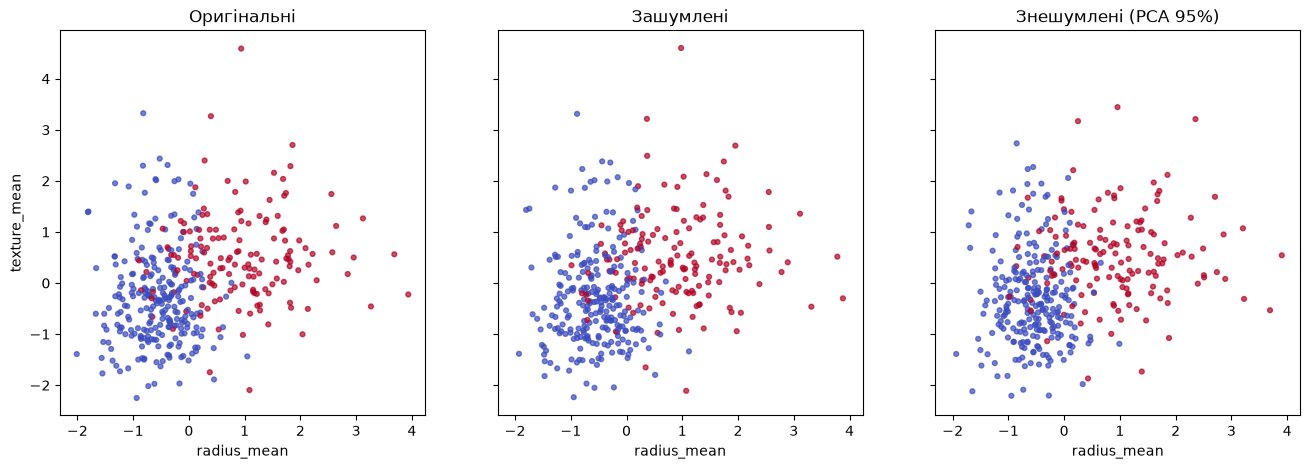

In [52]:
datasets = [X_train_norm, X_train_noisy, X_train_denoised]
names = ['Оригінальні', 'Зашумлені', 'Знешумлені (PCA 95%)']

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True, sharey=True)
for ax, data, name in zip(axes, datasets, names):
    ax.scatter(data['radius_mean'], data['texture_mean'],
               c=y_train, cmap='coolwarm', s=12, alpha=0.7)
    ax.set_title(name)
    ax.set_xlabel('radius_mean')
axes[0].set_ylabel('texture_mean')
plt.show()

Графік 2: усі 30 ознак одного пацієнта


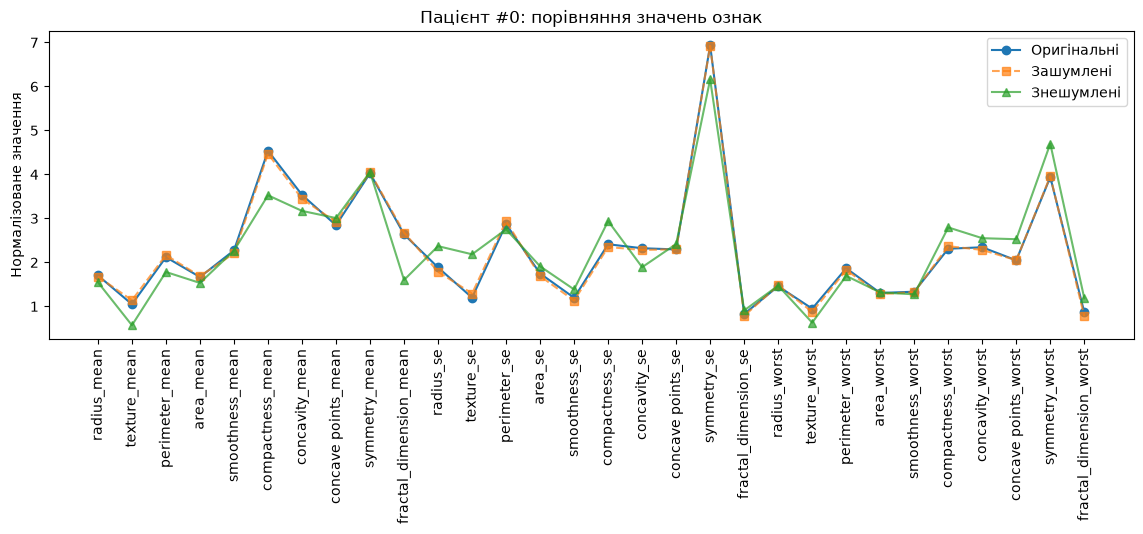

In [53]:
i = 0  # номер пацієнта
plt.figure(figsize=(14, 4))
plt.plot(X_train_norm.iloc[i].values,     'o-', label='Оригінальні')
plt.plot(X_train_noisy.iloc[i].values,    's--', label='Зашумлені', alpha=0.7)
plt.plot(X_train_denoised.iloc[i].values, '^-', label='Знешумлені', alpha=0.7)
plt.xticks(range(30), X_train_norm.columns, rotation=90)
plt.ylabel('Нормалізоване значення')
plt.title(f'Пацієнт #{i}: порівняння значень ознак')
plt.legend()
plt.show()

**Числове порівняння: наскільки дані відрізняються від оригіналу**

**MSE (середня квадратична помилка)** рахується так: для кожного числа беремо різницю з оригіналом, підносимо до квадрата, а потім усереднюємо по всіх числах. Чим менше, тим ближче до оригіналу.

In [54]:
mse_noisy = ((X_train_noisy - X_train_norm) ** 2).values.mean()
mse_denoised = ((X_train_denoised - X_train_norm) ** 2).values.mean()

print(f'Середня квадратична відстань до оригіналу:')
print(f'  зашумлені:  {mse_noisy:.4f}')
print(f'  знешумлені: {mse_denoised:.4f}')

Середня квадратична відстань до оригіналу:
  зашумлені:  0.0033
  знешумлені: 0.0490


Знешумлені дані виявилися в **~15 разів далі** від оригіналу, ніж зашумлені (на графіках зашумлена лінія майже збігається з початковою, а знешумлена помітно відхиляється).

**Чому так сталося?**
Доданий шум був мізерним, тоді як PCA для 95% відкинув цілих 5% загальної інформації. У ці 5% потрапила лише крапля шуму, а решта - це реальні дрібні відмінності між пацієнтами.

У результаті PCA прибрав трохи шуму, але разом із ним викинув у **~15 разів більше корисної інформації**.

## Завдання 5. Дерева рішень на зашумлених і знешумлених даних

**Дерева на знешумлених даних**

Знову використовуємо функцію з Частини 2.  
Вчимо на X_train_denoised, а перевіряємо на тому самому X_val_norm

In [55]:
trees_denoised, res_denoised = train_and_evaluate(
    X_train_denoised, y_train, X_val_norm, y_val, depths,
    title='Дерева на знешумлених даних (PCA 95%)')

Дерева на знешумлених даних (PCA 95%)


,max_depth,leaves,train_acc,val_acc
0,2,4,0.945,0.941
1,4,12,0.985,0.929
2,8,21,1.000,0.941


**Візуалізація дерев**

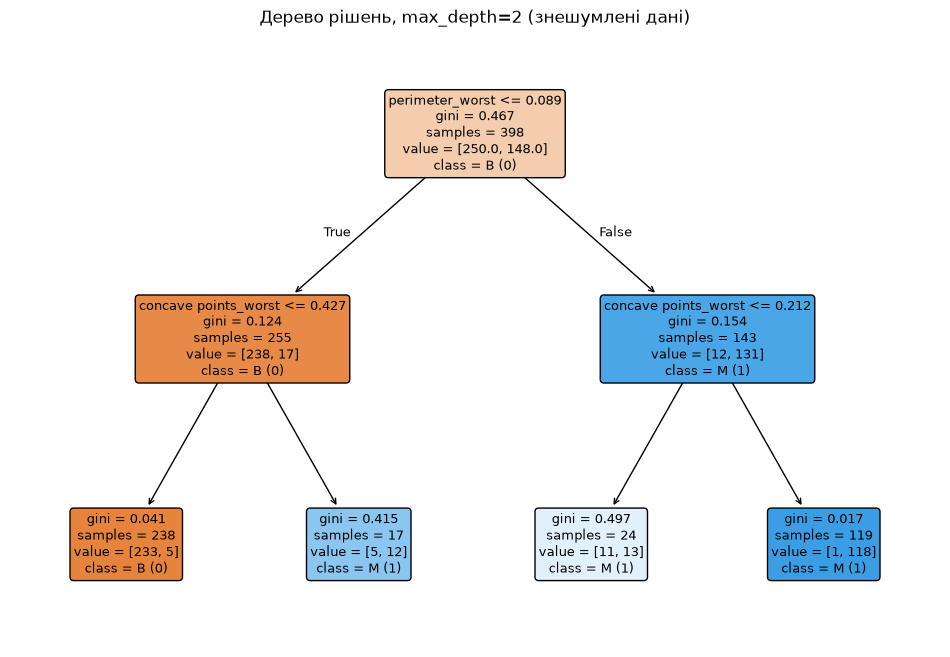

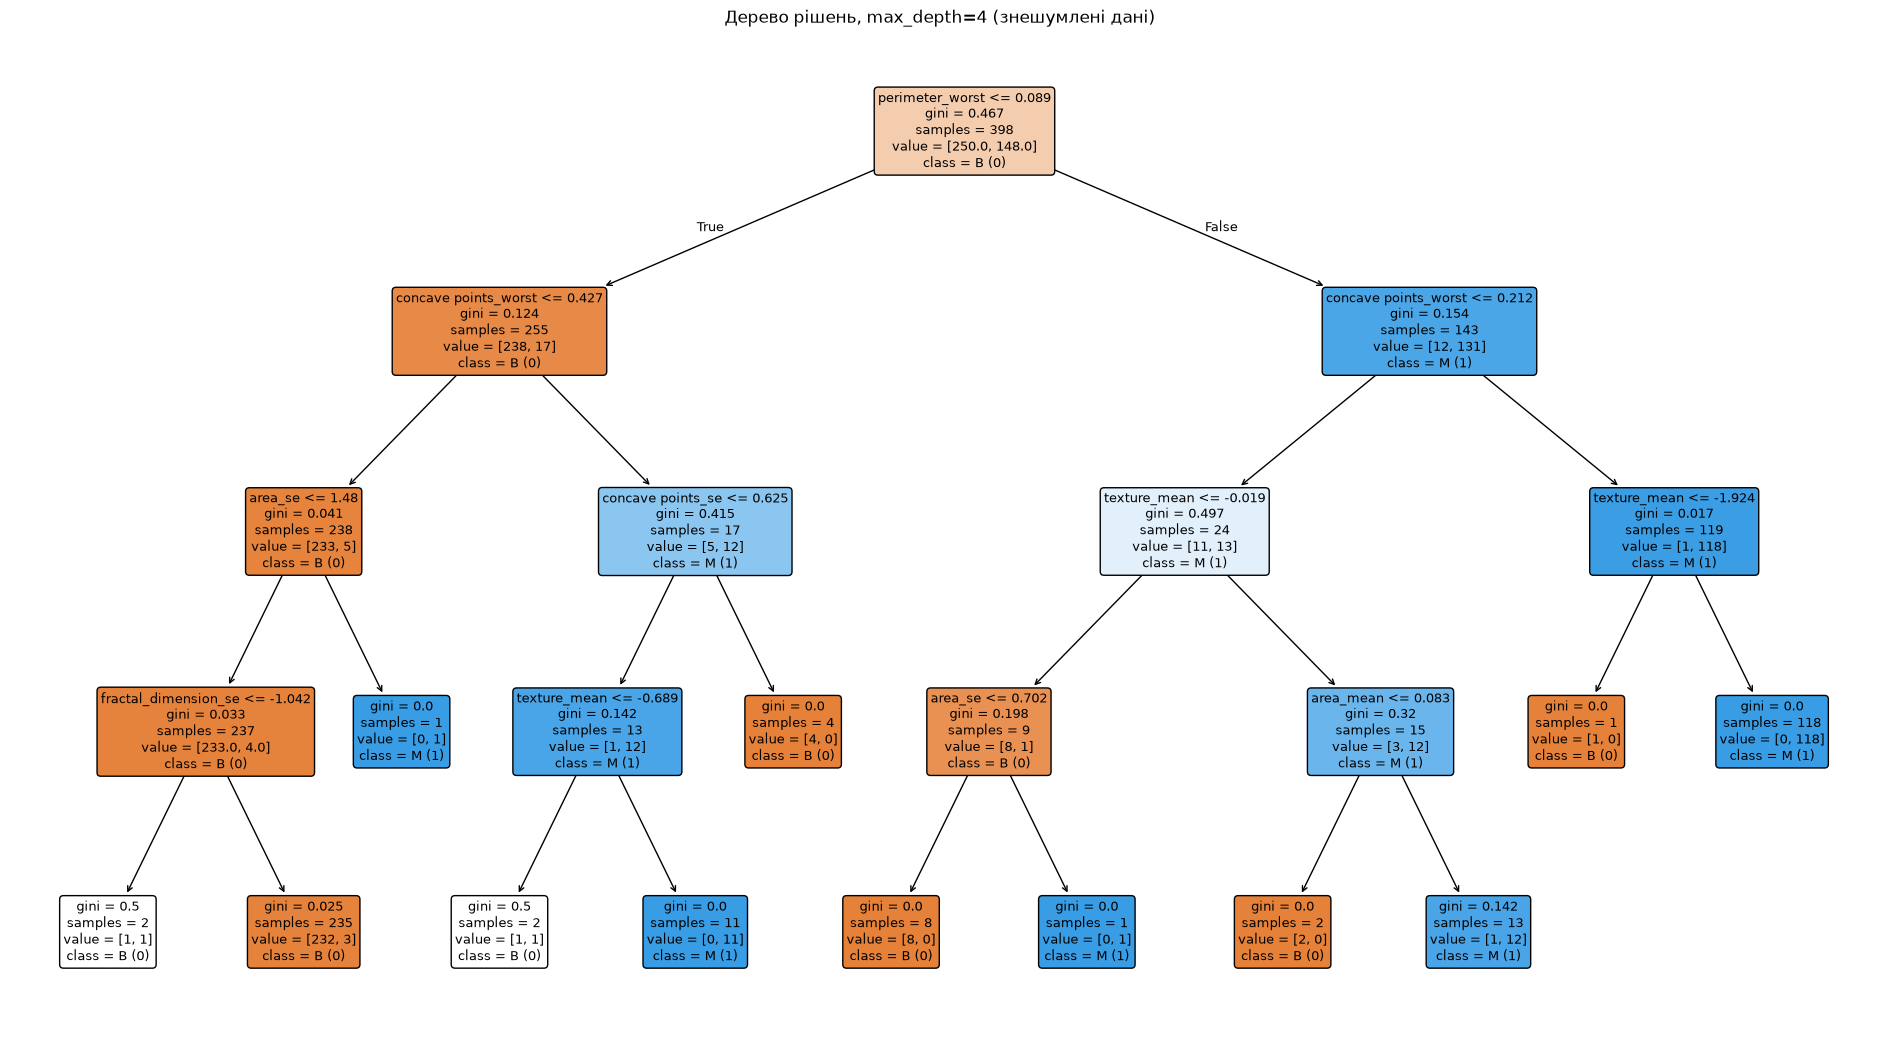

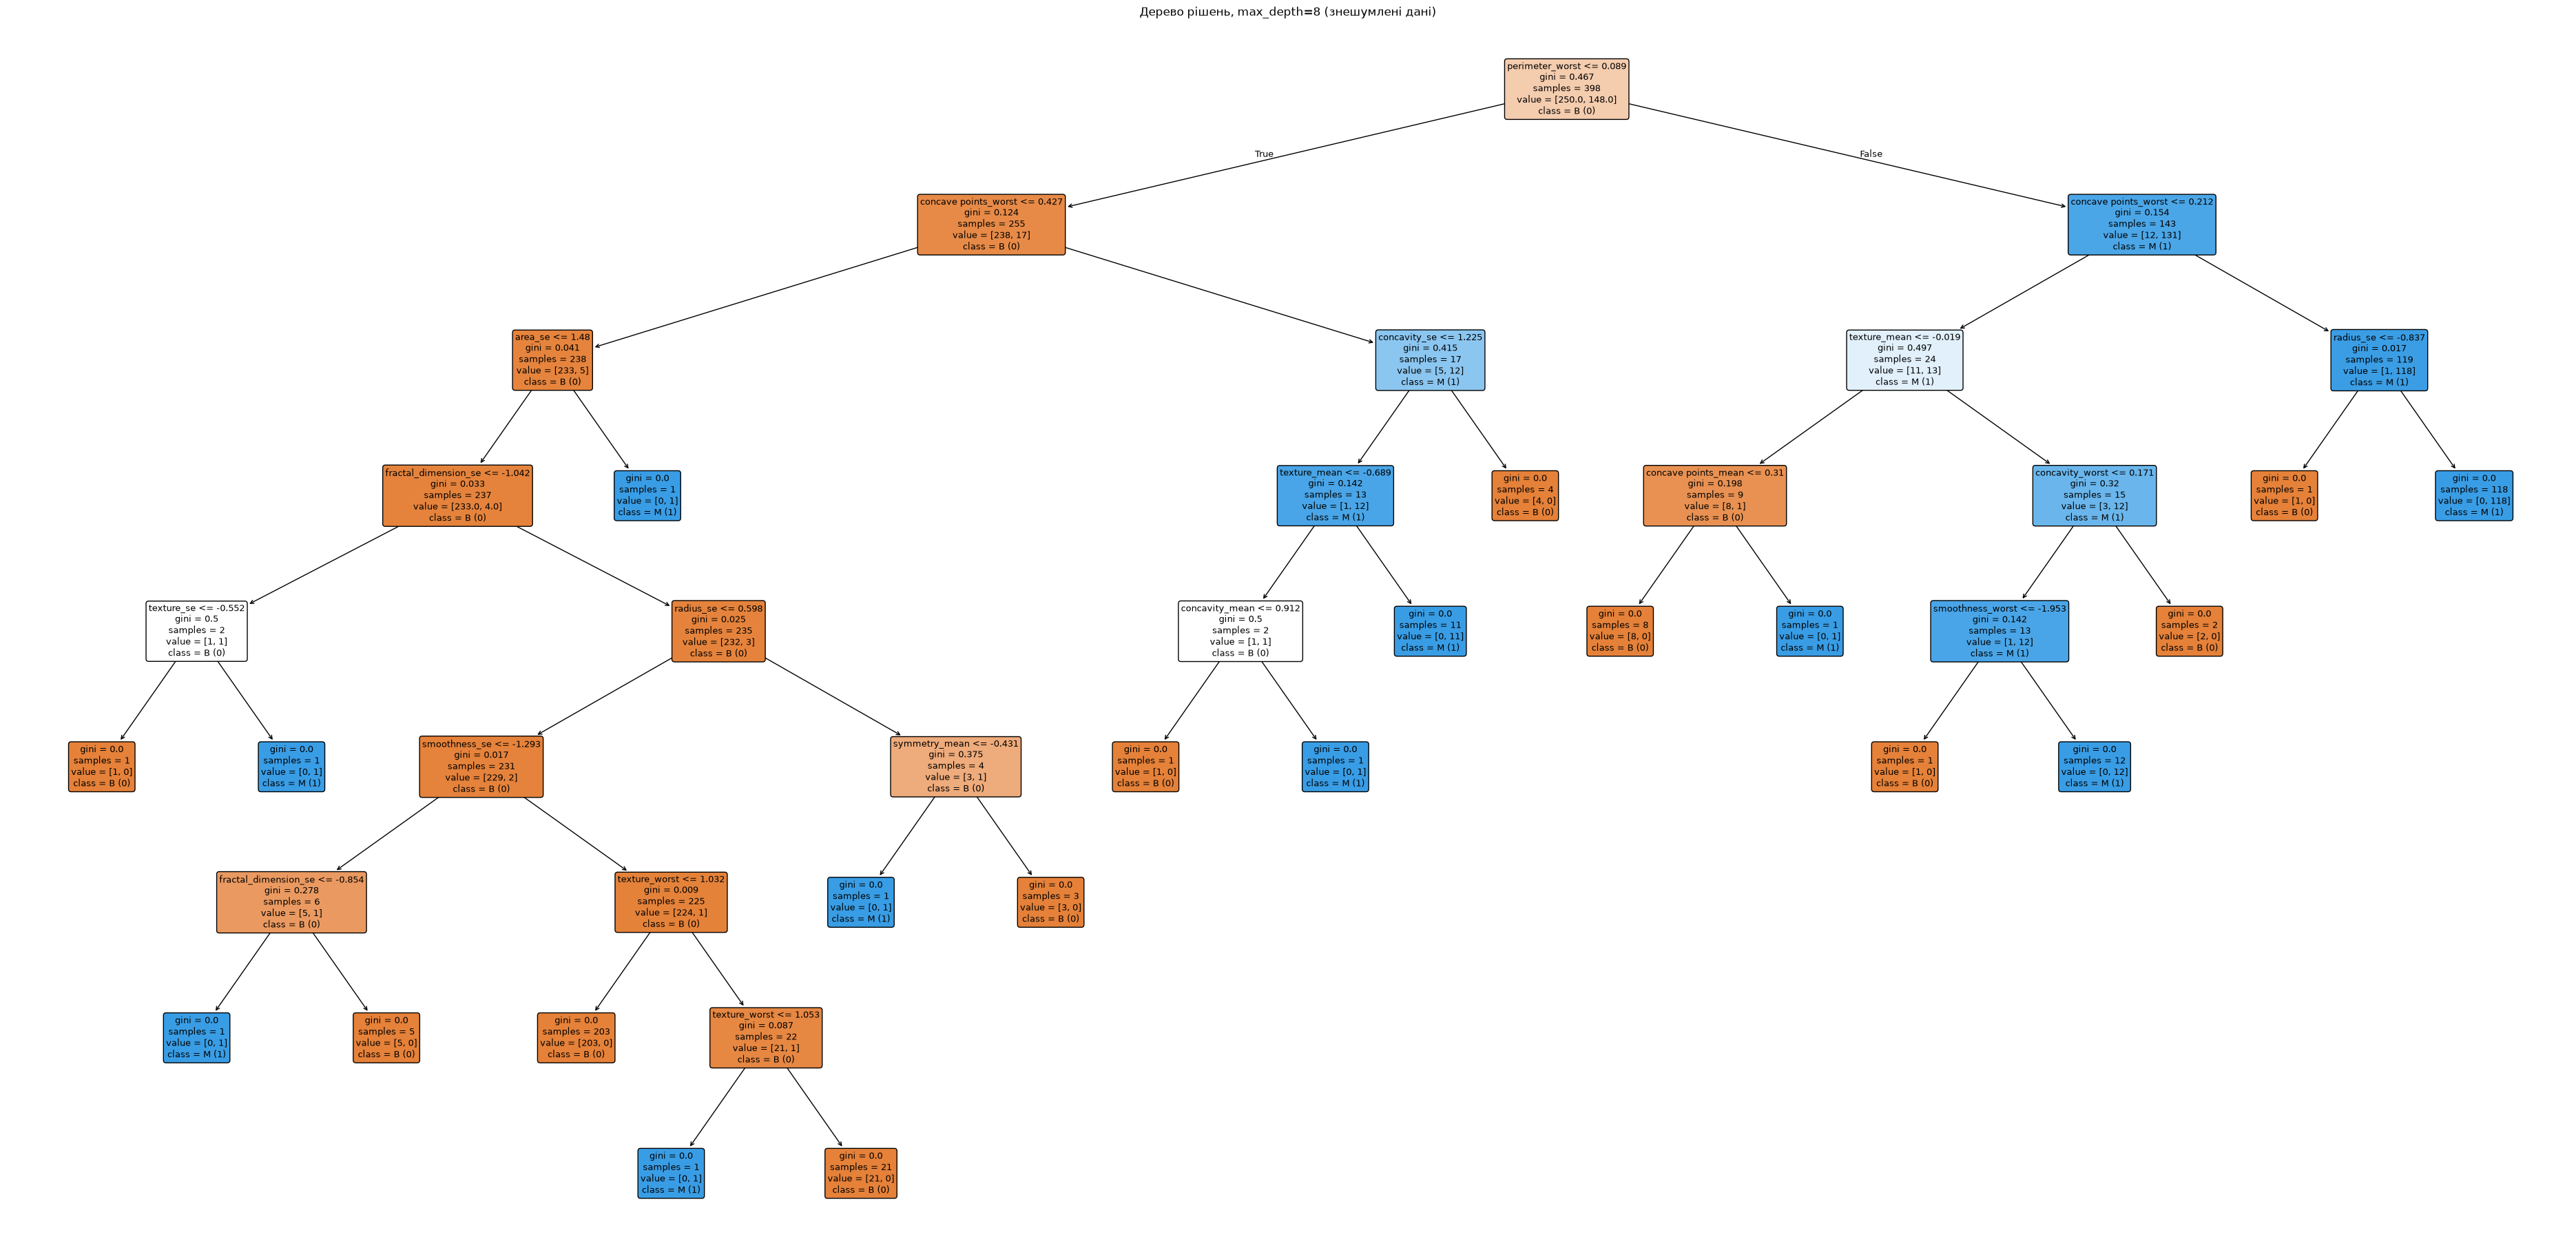

In [56]:
for d, tree in trees_denoised.items():
    plt.figure(figsize=(6 * d, 2.5 * d + 3))
    plot_tree(tree,
              feature_names=X_train_denoised.columns,
              class_names=['B (0)', 'M (1)'],
              filled=True, rounded=True, fontsize=9)
    plt.title(f'Дерево рішень, max_depth={d} (знешумлені дані)')
    plt.show()

**Зведена таблиця всіх результатів**

In [57]:
summary = pd.DataFrame({
    'max_depth':        depths,
    'train: чисті':      res_clean['train_acc'],
    'train: зашумлені':  res_noisy['train_acc'],
    'train: знешумлені': res_denoised['train_acc'],
    'val: чисті':        res_clean['val_acc'],
    'val: зашумлені':    res_noisy['val_acc'],
    'val: знешумлені':   res_denoised['val_acc'],
})
summary

,max_depth,train: чисті,train: зашумлені,train: знешумлені,val: чисті,val: зашумлені,val: знешумлені
0,2,0.950,0.952,0.945,0.882,0.894,0.941
1,4,0.977,0.975,0.985,0.894,0.882,0.929
2,8,1.000,0.997,1.000,0.894,0.906,0.941


**Фінальний графік порівняння**


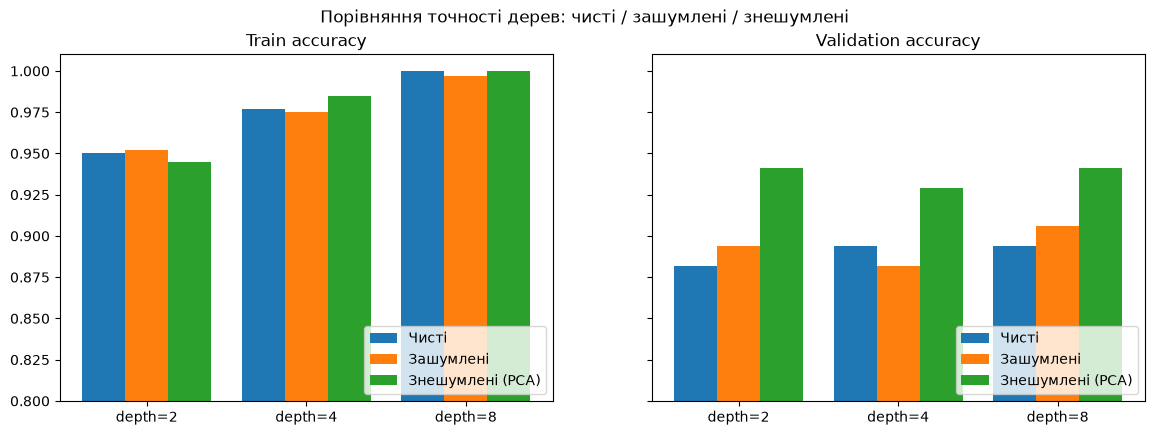

In [58]:
x = np.arange(len(depths))
w = 0.27
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)

for ax, col, name in zip(axes, ['train_acc', 'val_acc'], ['Train', 'Validation']):
    ax.bar(x - w, res_clean[col],    width=w, label='Чисті')
    ax.bar(x,     res_noisy[col],    width=w, label='Зашумлені')
    ax.bar(x + w, res_denoised[col], width=w, label='Знешумлені (PCA)')
    ax.set_xticks(x)
    ax.set_xticklabels([f'depth={d}' for d in depths])
    ax.set_title(f'{name} accuracy')
    ax.set_ylim(0.8, 1.01)
    ax.legend(loc='lower right')

plt.suptitle('Порівняння точності дерев: чисті / зашумлені / знешумлені')
plt.show()

**Висновок:** Дерева на знешумлених даних показали найкращу точність, хоча математично вони найсильніше відхиляються від оригіналу.  
Чому так вийшло:  
1. PCA спрацював як регуляризація: він відкинув дрібні індивідуальні деталі, на яких моделі перенавчалися, і залишив лише головні закономірності хвороби.  
2. Стабільність: кожна відновлена ознака увібрала в себе інформацію з кількох початкових, що зробило розбиття в деревах надійнішими.

## Загальні висновки

У ході лабораторної роботи на датасеті Breast Cancer Wisconsin (569 пацієнтів, 30 ознак, класифікація M/B) було:
- підготовлено дані: видалено порожню колонку та `id`, розбито на train/val/test (70/15/15) зі стратифікацією, нормалізовано за статистиками train;
- побудовано дерева рішень глибини 2, 4 і 8. Глибші дерева краще запам'ятовують train (до 100%), але не покращують точність на валідації (≈0.89), що свідчить про перенавчання;
- додано рівномірний шум [−0.1, 0.1]; він практично не вплинув на дерева, бо є малим порівняно з розкидом нормалізованих даних;
- за допомогою PCA показано, що 10 компонент з 30 пояснюють 95% дисперсії, а вже перша компонента добре розділяє класи;
- реконструкція даних через PCA (95%) не наблизила їх до оригіналу (MSE 0.049 проти 0.0033), але дерева на знешумлених даних показали найкращу точність на валідації (до 0.941), оскільки PCA прибрав дрібні деталі, на яких дерева перенавчаються.

## Відповіді на запитання

*   **Дерево рішень** - модель із запитань «так/ні», які послідовно ділять дані на чистіші групи.
*   **Розбиття** - перебираємо всі ознаки й пороги, обираємо те, що дає найменший Gini (або найбільший Information Gain).
*   **Ентропія** - міра хаосу у вузлі, IG - наскільки розбиття цей хаос зменшило.
*   **PCA** - перетворення корельованих ознак у незалежні компоненти, впорядковані за важливістю.
*   **Особливості компонент** - некорельовані, впорядковані, є лінійними комбінаціями старих ознак, важко інтерпретуються.
*   **Знешумлення** - сигнал зосереджений у перших компонентах, шум розмазаний по всіх. Відкидаємо останні - відкидаємо шум.
*   **Результати** - слабкий шум не вплинув, а PCA допоміг як регуляризація, а не як відновлення даних.